In [1]:
import pandas as pd
import numpy as np

In [2]:
df=pd.read_csv('titanic.csv')
print(df.head())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  


In [3]:
print(
    df.shape
)
print(df.columns)
print(df.info())
print(df.describe())

(891, 12)
Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB
None
       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.

In [4]:
print(df.tail())

     PassengerId  Survived  Pclass                                      Name  \
886          887         0       2                     Montvila, Rev. Juozas   
887          888         1       1              Graham, Miss. Margaret Edith   
888          889         0       3  Johnston, Miss. Catherine Helen "Carrie"   
889          890         1       1                     Behr, Mr. Karl Howell   
890          891         0       3                       Dooley, Mr. Patrick   

        Sex   Age  SibSp  Parch      Ticket   Fare Cabin Embarked  
886    male  27.0      0      0      211536  13.00   NaN        S  
887  female  19.0      0      0      112053  30.00   B42        S  
888  female   NaN      1      2  W./C. 6607  23.45   NaN        S  
889    male  26.0      0      0      111369  30.00  C148        C  
890    male  32.0      0      0      370376   7.75   NaN        Q  


In [5]:
print(df['Sex'].unique())

<StringArray>
['male', 'female']
Length: 2, dtype: str


In [6]:
print(df['Pclass'].unique())

[3 1 2]


In [7]:
print(df['Embarked'].unique())
print(df.dtypes)

<StringArray>
['S', 'C', 'Q', nan]
Length: 4, dtype: str
PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object


In [8]:
df = df.drop(['PassengerId', 'Name', 'Ticket', 'Cabin'], axis=1)

print(df.head())

   Survived  Pclass     Sex   Age  SibSp  Parch     Fare Embarked
0         0       3    male  22.0      1      0   7.2500        S
1         1       1  female  38.0      1      0  71.2833        C
2         1       3  female  26.0      0      0   7.9250        S
3         1       1  female  35.0      1      0  53.1000        S
4         0       3    male  35.0      0      0   8.0500        S


In [9]:
df['FamilySize']=df['SibSp']+df['Parch']+1
print(df.head())

   Survived  Pclass     Sex   Age  SibSp  Parch     Fare Embarked  FamilySize
0         0       3    male  22.0      1      0   7.2500        S           2
1         1       1  female  38.0      1      0  71.2833        C           2
2         1       3  female  26.0      0      0   7.9250        S           1
3         1       1  female  35.0      1      0  53.1000        S           2
4         0       3    male  35.0      0      0   8.0500        S           1


In [10]:
df['Alone']=np.where(df['FamilySize']==1,'Yes','No')
print(df.head())

   Survived  Pclass     Sex   Age  SibSp  Parch     Fare Embarked  FamilySize  \
0         0       3    male  22.0      1      0   7.2500        S           2   
1         1       1  female  38.0      1      0  71.2833        C           2   
2         1       3  female  26.0      0      0   7.9250        S           1   
3         1       1  female  35.0      1      0  53.1000        S           2   
4         0       3    male  35.0      0      0   8.0500        S           1   

  Alone  
0    No  
1    No  
2   Yes  
3    No  
4   Yes  


In [11]:
print(df.isnull().mean()*100)

Survived       0.000000
Pclass         0.000000
Sex            0.000000
Age           19.865320
SibSp          0.000000
Parch          0.000000
Fare           0.000000
Embarked       0.224467
FamilySize     0.000000
Alone          0.000000
dtype: float64


In [12]:
df['Age'] = df['Age'].fillna(df['Age'].mean())
print(df)

     Survived  Pclass     Sex        Age  SibSp  Parch     Fare Embarked  \
0           0       3    male  22.000000      1      0   7.2500        S   
1           1       1  female  38.000000      1      0  71.2833        C   
2           1       3  female  26.000000      0      0   7.9250        S   
3           1       1  female  35.000000      1      0  53.1000        S   
4           0       3    male  35.000000      0      0   8.0500        S   
..        ...     ...     ...        ...    ...    ...      ...      ...   
886         0       2    male  27.000000      0      0  13.0000        S   
887         1       1  female  19.000000      0      0  30.0000        S   
888         0       3  female  29.699118      1      2  23.4500        S   
889         1       1    male  26.000000      0      0  30.0000        C   
890         0       3    male  32.000000      0      0   7.7500        Q   

     FamilySize Alone  
0             2    No  
1             2    No  
2             1

In [13]:
df['Fare']=df['Fare'].fillna(df['Fare'].mean())
print(df)

     Survived  Pclass     Sex        Age  SibSp  Parch     Fare Embarked  \
0           0       3    male  22.000000      1      0   7.2500        S   
1           1       1  female  38.000000      1      0  71.2833        C   
2           1       3  female  26.000000      0      0   7.9250        S   
3           1       1  female  35.000000      1      0  53.1000        S   
4           0       3    male  35.000000      0      0   8.0500        S   
..        ...     ...     ...        ...    ...    ...      ...      ...   
886         0       2    male  27.000000      0      0  13.0000        S   
887         1       1  female  19.000000      0      0  30.0000        S   
888         0       3  female  29.699118      1      2  23.4500        S   
889         1       1    male  26.000000      0      0  30.0000        C   
890         0       3    male  32.000000      0      0   7.7500        Q   

     FamilySize Alone  
0             2    No  
1             2    No  
2             1

In [14]:
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
print(df)

     Survived  Pclass     Sex        Age  SibSp  Parch     Fare Embarked  \
0           0       3    male  22.000000      1      0   7.2500        S   
1           1       1  female  38.000000      1      0  71.2833        C   
2           1       3  female  26.000000      0      0   7.9250        S   
3           1       1  female  35.000000      1      0  53.1000        S   
4           0       3    male  35.000000      0      0   8.0500        S   
..        ...     ...     ...        ...    ...    ...      ...      ...   
886         0       2    male  27.000000      0      0  13.0000        S   
887         1       1  female  19.000000      0      0  30.0000        S   
888         0       3  female  29.699118      1      2  23.4500        S   
889         1       1    male  26.000000      0      0  30.0000        C   
890         0       3    male  32.000000      0      0   7.7500        Q   

     FamilySize Alone  
0             2    No  
1             2    No  
2             1

In [15]:
print(df.isnull().sum())
print(df['Survived'].value_counts())

Survived      0
Pclass        0
Sex           0
Age           0
SibSp         0
Parch         0
Fare          0
Embarked      0
FamilySize    0
Alone         0
dtype: int64
Survived
0    549
1    342
Name: count, dtype: int64


In [16]:
print(df.groupby('Sex')['Survived'].mean() * 100)
print(df.groupby('Pclass')['Survived'].mean())

Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64
Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64


In [19]:
pip install matplotlib seaborn


   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.3 MB 661.2 kB/s eta 0:00:14
   -- ------------------------------------- 0.5/9.3 MB 661.2 kB/s eta 0:00:14
   --- ------------------------------------ 0.8/9.3 MB 747.2 kB/s eta 0:00:12
   --- ------------------------------------ 0.8/9.3 MB 747.2 kB/s eta 0:00:12
   ---- ----------------------------------- 1.0/9.3 MB 652.6 kB/s eta 0:00:13
   ---- ----------------------------------- 1.0/9.3 MB 652.6 kB/s eta 0:00:13
   ----- ---------------------------------- 1.3/9.3 MB 646.8 kB/s eta 0:00:13
   ----- ---------------------------------- 1.3/9.3 MB 646.8 kB/s eta 0:00:13
   ----- ---------------------------------- 1.3/9.3 MB 646.8 kB/s eta 0:00:13
   ------ --------------------------------- 1.6/9.3 MB 585.8 kB/s eta 0:00:14
   ------ ---


[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

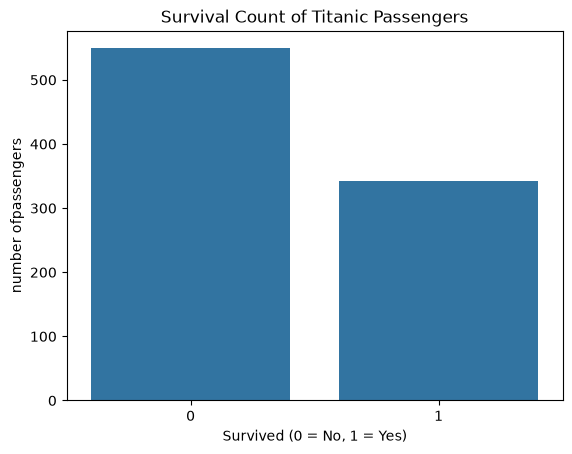

In [22]:
sns.countplot(data=df, x='Survived')
plt.title('Survival Count of Titanic Passengers')
plt.xlabel('Survived (0 = No, 1 = Yes)')
plt.ylabel("number ofpassengers")
plt.show()

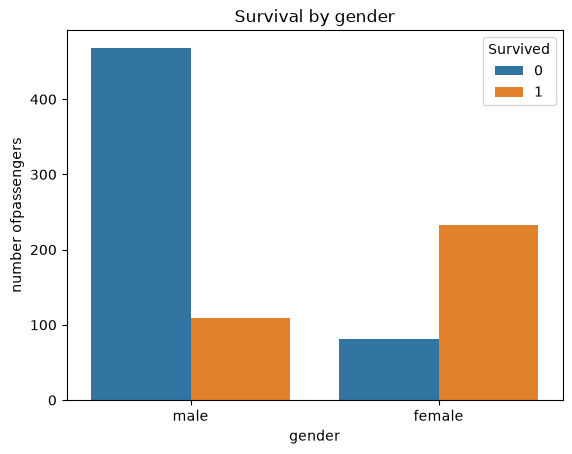

In [23]:
sns.countplot(data=df, x='Sex', hue='Survived')
plt.title('Survival by gender')
plt.xlabel('gender')
plt.ylabel("number ofpassengers")
plt.show()

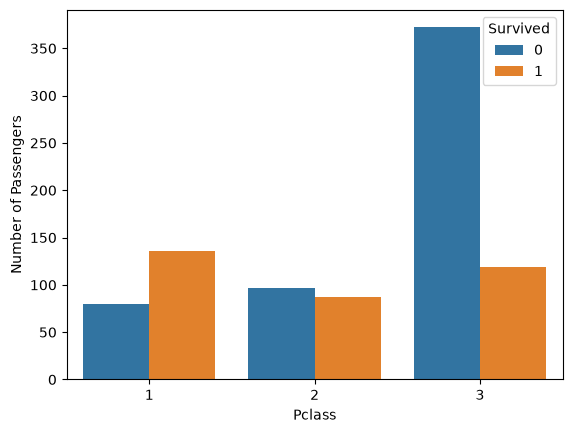

In [24]:
sns.countplot(data=df, x='Pclass', hue='Survived')
plt.ylabel('Number of Passengers')
plt.show()

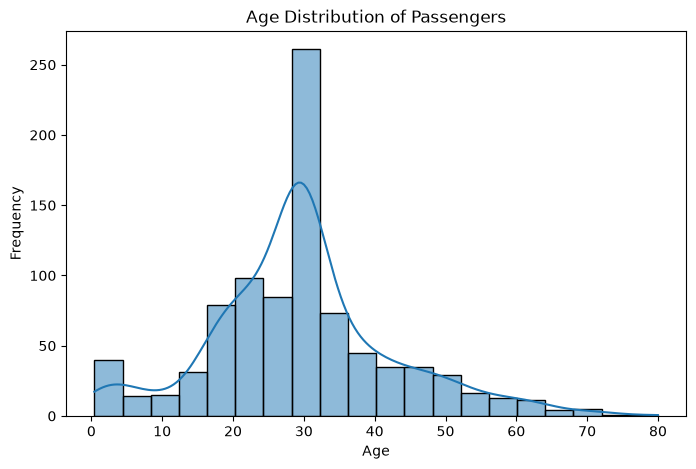

In [25]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Age', bins=20, kde=True)
plt.title('Age Distribution of Passengers')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

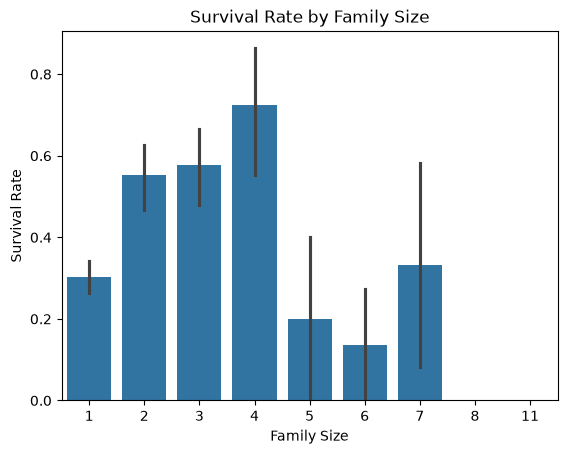

In [26]:
sns.barplot(data=df, x='FamilySize', y='Survived')
plt.title('Survival Rate by Family Size')
plt.xlabel('Family Size')
plt.ylabel('Survival Rate')
plt.show()